<a href="https://colab.research.google.com/github/laboratoriodecodigos/Colab-Python/blob/main/redes_neuronales_pytorch_basico_a_avanzado.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Redes neuronales en PyTorch: de una neurona a un Transformer
**Laboratorio de Códigos** · Notebook de referencia (Colab, activa GPU: *Entorno de ejecución → Cambiar tipo → T4 GPU*)

| Nivel | Modelo | Qué aprendes |
|---|---|---|
| 1 | Neurona a mano | tensores, autograd, descenso de gradiente |
| 2 | `nn.Linear` | `nn.Module`, loss, optimizador |
| 3 | MLP | no linealidad (ReLU) + **video** de la frontera de decisión |
| 4 | MLP en MNIST | DataLoader, entrenamiento por lotes |
| 5 | CNN | convoluciones, filtros, mapas de características |
| 6 | Mini-ResNet | conexiones residuales, BatchNorm, AdamW, OneCycle |
| 7 | Tiny Vision Transformer | atención, parches, `TransformerEncoder` |

In [1]:
import time, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.datasets import make_moons
from matplotlib.animation import FuncAnimation, FFMpegWriter
from IPython.display import HTML, display
from base64 import b64encode

device = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(42); np.random.seed(42)
print("PyTorch", torch.__version__, "| dispositivo:", device)

def show_video(path, width=480):
    data = b64encode(open(path, "rb").read()).decode()
    display(HTML(f'<video width="{width}" controls autoplay loop><source src="data:video/mp4;base64,{data}" type="video/mp4"></video>'))

def n_params(m): return sum(p.numel() for p in m.parameters())
results = {}   # aquí guardamos la comparativa final

PyTorch 2.14.1+cpu | dispositivo: cpu


## 🔹 Nivel 1 · Una neurona "a mano"
Aprendemos `y = w·x + b` con **autograd**, sin `nn` ni optimizadores.

w = 2.00 (real 2.0) | b = 1.02 (real 1.0)


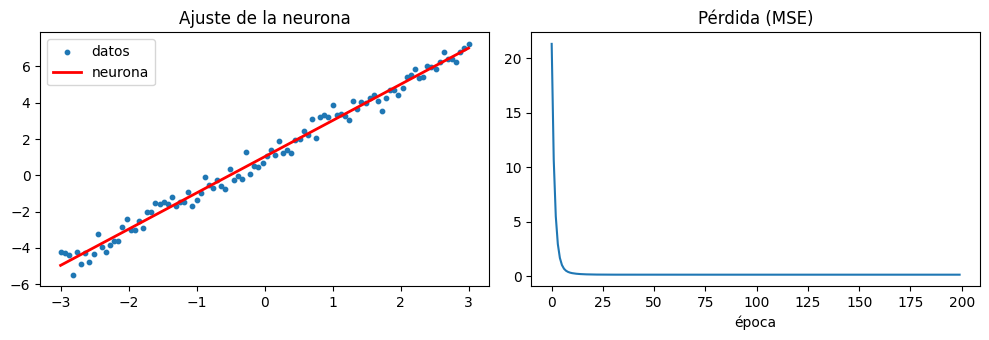

In [2]:
x = torch.linspace(-3, 3, 100).unsqueeze(1)
y = 2 * x + 1 + 0.4 * torch.randn_like(x)

w = torch.randn(1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lr, losses = 0.05, []

for epoch in range(200):
    pred = x * w + b
    loss = ((pred - y) ** 2).mean()      # MSE
    loss.backward()                       # gradientes automáticos
    with torch.no_grad():                 # paso de descenso de gradiente
        w -= lr * w.grad
        b -= lr * b.grad
    w.grad.zero_(); b.grad.zero_()
    losses.append(loss.item())

print(f"w = {w.item():.2f} (real 2.0) | b = {b.item():.2f} (real 1.0)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].scatter(x, y, s=10, label="datos")
ax[0].plot(x, (x * w + b).detach(), "r", lw=2, label="neurona")
ax[0].set_title("Ajuste de la neurona"); ax[0].legend()
ax[1].plot(losses); ax[1].set_title("Pérdida (MSE)"); ax[1].set_xlabel("época")
plt.tight_layout(); plt.show()

## 🔹 Nivel 2 · La misma neurona con `nn.Module`
PyTorch se encarga de parámetros, pérdida y optimizador.

In [3]:
model = nn.Linear(1, 1)
loss_fn = nn.MSELoss()
opt = torch.optim.SGD(model.parameters(), lr=0.05)

for epoch in range(200):
    opt.zero_grad()
    loss = loss_fn(model(x), y)
    loss.backward()
    opt.step()

print("Pesos:", model.weight.item(), "| sesgo:",
      model.bias.item(), "| parámetros:", n_params(model))
results["1-2 Neurona"] = (None, n_params(model))

Pesos: 1.9960697889328003 | sesgo: 1.023905634880066 | parámetros: 2


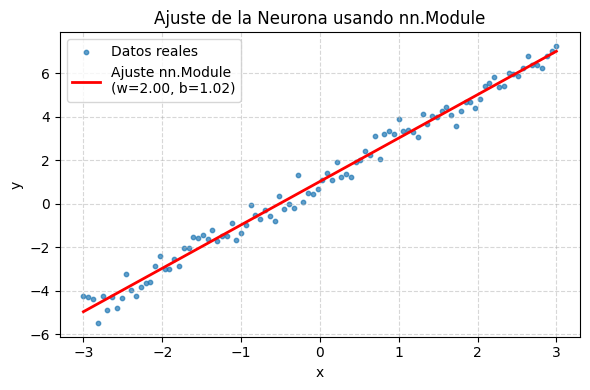

In [5]:
# Graficar el resultado de la neurona entrenada con nn.Module
with torch.no_grad():
    predictions = model(x).cpu().numpy()

plt.figure(figsize=(6, 4))
plt.scatter(x.cpu().numpy(), y.cpu().numpy(), s=10, label="Datos reales", alpha=0.7)
plt.plot(x.cpu().numpy(), predictions, color="red", linewidth=2, label=f"Ajuste nn.Module\n(w={model.weight.item():.2f}, b={model.bias.item():.2f})")
plt.title("Ajuste de la Neurona usando nn.Module")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 🔹 Nivel 3 · Red multicapa (MLP) + 🎬 VIDEO de la frontera de decisión
Una sola neurona solo dibuja rectas. Con capas ocultas + **ReLU** la red aprende curvas.

In [4]:
Xn, yn = make_moons(1500, noise=0.25, random_state=0)
X = torch.tensor(Xn, dtype=torch.float32).to(device)
Y = torch.tensor(yn, dtype=torch.float32).unsqueeze(1).to(device)

class MLP(nn.Module):
    def __init__(self, i=2, h=32, o=1):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(i, h), nn.ReLU(),
            nn.Linear(h, h), nn.ReLU(),
            nn.Linear(h, o))
    def forward(self, x): return self.net(x)

mlp = MLP().to(device)
opt = torch.optim.Adam(mlp.parameters(), lr=0.01)
loss_fn = nn.BCEWithLogitsLoss()

xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32).to(device)

frames = []
for epoch in range(1, 201):
    opt.zero_grad()
    loss = loss_fn(mlp(X), Y)
    loss.backward(); opt.step()
    if epoch == 1 or epoch % 5 == 0:
        with torch.no_grad():
            p = torch.sigmoid(mlp(grid)).cpu().numpy().reshape(xx.shape)
        frames.append((epoch, p, loss.item()))

acc = ((torch.sigmoid(mlp(X)) > 0.5).float() == Y).float().mean().item()
print(f"Precisión: {acc:.3f} | parámetros: {n_params(mlp)}")

fig, ax = plt.subplots(figsize=(5, 4))
def update(i):
    ax.clear(); e, p, l = frames[i]
    ax.contourf(xx, yy, p, levels=20, cmap="RdBu", alpha=0.75)
    ax.scatter(Xn[:, 0], Xn[:, 1], c=yn, cmap="RdBu", edgecolor="k", s=10)
    ax.set_title(f"Época {e} | loss {l:.3f}")
ani = FuncAnimation(fig, update, frames=len(frames), interval=120)
ani.save("frontera.mp4", writer=FFMpegWriter(fps=8))
plt.close(fig)
show_video("frontera.mp4")
results["3 MLP (moons)"] = (acc, n_params(mlp))

Precisión: 0.942 | parámetros: 1185


## 📦 Datos reales: MNIST
Preparamos `Dataset` + `DataLoader` y definimos funciones de entrenamiento reutilizables para los niveles 4 a 7.

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 363kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.19MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.73MB/s]


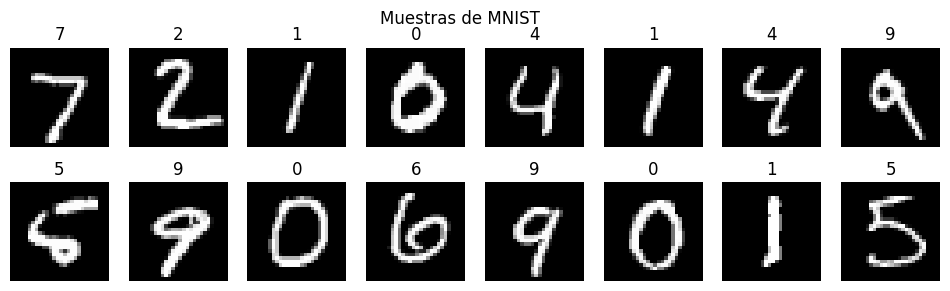

In [6]:
norm = transforms.Normalize((0.1307,), (0.3081,))
tfm = transforms.Compose([transforms.ToTensor(), norm])
train_ds = datasets.MNIST("data", train=True, download=True, transform=tfm)
test_ds  = datasets.MNIST("data", train=False, download=True, transform=tfm)
train_dl = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2)
test_dl  = DataLoader(test_ds, batch_size=512)

fig, axs = plt.subplots(2, 8, figsize=(12, 3.2))
for a, (img, lab) in zip(axs.flat, [test_ds[i] for i in range(16)]):
    a.imshow(img.squeeze() * 0.3081 + 0.1307, cmap="gray"); a.set_title(lab); a.axis("off")
plt.suptitle("Muestras de MNIST"); plt.show()

def evaluate(model, dl):
    model.eval(); correct = n = 0
    with torch.no_grad():
        for xb, yb in dl:
            xb, yb = xb.to(device), yb.to(device)
            correct += (model(xb).argmax(1) == yb).sum().item(); n += len(yb)
    return correct / n

def fit(model, train_dl, test_dl, epochs, opt, sched=None, loss_fn=None, clip=None):
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    hist = {"loss": [], "acc": []}
    for ep in range(epochs):
        model.train(); tot = 0; t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            if clip: nn.utils.clip_grad_norm_(model.parameters(), clip)
            opt.step()
            if sched: sched.step()
            tot += loss.item() * len(yb)
        acc = evaluate(model, test_dl)
        hist["loss"].append(tot / len(train_dl.dataset)); hist["acc"].append(acc)
        print(f"Época {ep+1}/{epochs} | loss {hist['loss'][-1]:.4f} | acc {acc:.4f} | {time.time()-t0:.1f}s")
    return hist

def show_predictions(model, n=16, title=""):
    model.eval()
    imgs, labs = next(iter(test_dl))
    with torch.no_grad(): preds = model(imgs[:n].to(device)).argmax(1).cpu()
    fig, axs = plt.subplots(2, n // 2, figsize=(12, 3.5))
    for a, im, l, p in zip(axs.flat, imgs, labs, preds):
        a.imshow(im.squeeze() * 0.3081 + 0.1307, cmap="gray"); a.axis("off")
        a.set_title(f"{p.item()}", color="green" if p == l else "red")
    plt.suptitle(f"Predicciones {title} (verde = acierto)"); plt.show()

## 🔹 Nivel 4 · MLP para imágenes (MNIST)

Época 1/3 | loss 0.2701 | acc 0.9660 | 15.4s
Época 2/3 | loss 0.1024 | acc 0.9680 | 14.9s
Época 3/3 | loss 0.0687 | acc 0.9721 | 16.0s


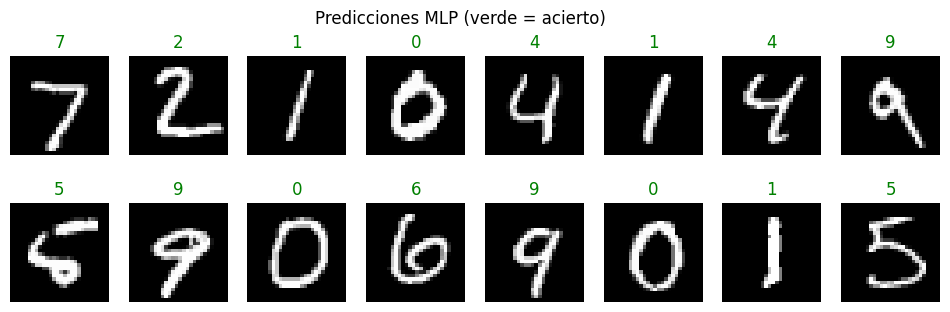

In [7]:
mlp_mnist = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(),
    nn.Linear(256, 128), nn.ReLU(),
    nn.Linear(128, 10)).to(device)

h4 = fit(mlp_mnist, train_dl, test_dl, epochs=3, opt=torch.optim.Adam(mlp_mnist.parameters(), 1e-3))
show_predictions(mlp_mnist, title="MLP")
results["4 MLP MNIST"] = (h4["acc"][-1], n_params(mlp_mnist))

## 🔹 Nivel 5 · Red convolucional (CNN)
Las convoluciones respetan la estructura 2D de la imagen. Además de entrenar, **miramos dentro** de la red.

Época 1/3 | loss 0.1940 | acc 0.9841 | 51.9s
Época 2/3 | loss 0.0639 | acc 0.9855 | 48.1s
Época 3/3 | loss 0.0501 | acc 0.9875 | 47.8s


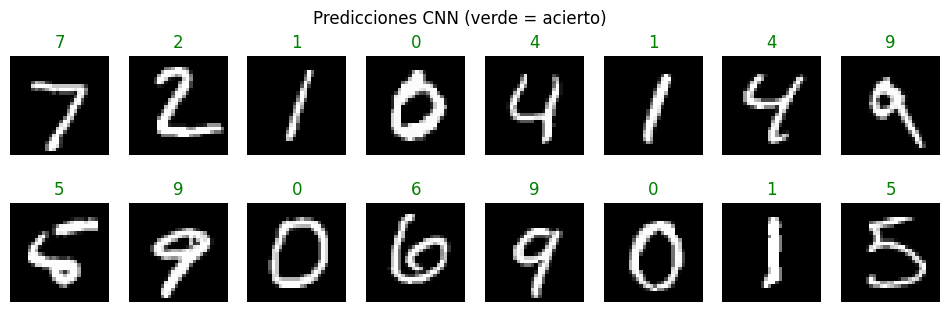

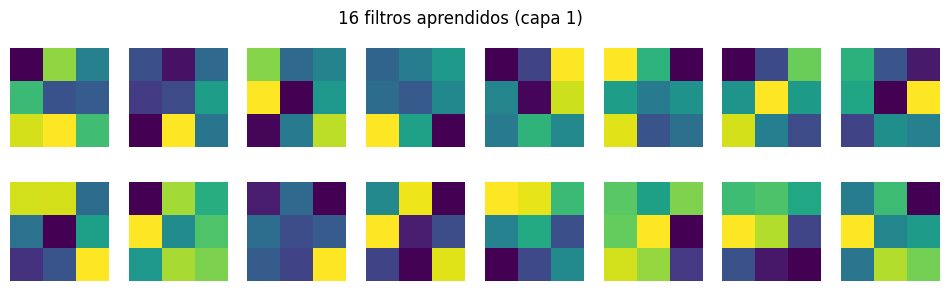

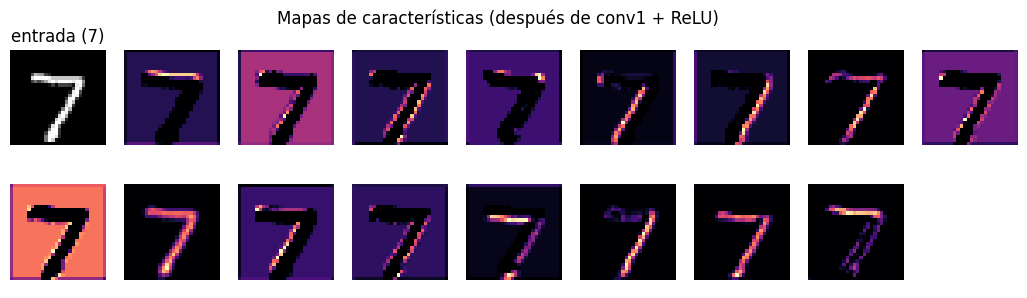

In [8]:
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(32 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(0.3), nn.Linear(128, 10))
    def forward(self, x): return self.classifier(self.features(x))

cnn = CNN().to(device)
h5 = fit(cnn, train_dl, test_dl, epochs=3, opt=torch.optim.Adam(cnn.parameters(), 1e-3))
show_predictions(cnn, title="CNN")
results["5 CNN"] = (h5["acc"][-1], n_params(cnn))

# 👀 Filtros aprendidos de la primera capa
filters = cnn.features[0].weight.detach().cpu()
fig, axs = plt.subplots(2, 8, figsize=(12, 3.2))
for a, f in zip(axs.flat, filters):
    a.imshow(f[0], cmap="viridis"); a.axis("off")
plt.suptitle("16 filtros aprendidos (capa 1)"); plt.show()

# 👀 Mapas de características para un dígito
img, lab = test_ds[0]
cnn.eval()
with torch.no_grad(): fmap = cnn.features[:3](img.unsqueeze(0).to(device)).squeeze().cpu()
fig, axs = plt.subplots(2, 9, figsize=(13, 3.2))
axs[0, 0].imshow(img.squeeze(), cmap="gray"); axs[0, 0].set_title(f"entrada ({lab})")
for a in axs.flat: a.axis("off")
for k in range(16):
    r, c = divmod(k, 8); ax_ = axs[r, c + 1] if r == 0 else axs[1, c]
    ax_.imshow(fmap[k], cmap="magma")
plt.suptitle("Mapas de características (después de conv1 + ReLU)"); plt.show()

## 🔹 Nivel 6 · Mini-ResNet (avanzado)
Conexiones **residuales** + BatchNorm + **AdamW** + scheduler **OneCycle** + aumento de datos + *gradient clipping*.

Época 1/4 | loss 1.1297 | acc 0.9597 | 152.3s
Época 2/4 | loss 0.5923 | acc 0.9891 | 155.2s
Época 3/4 | loss 0.5607 | acc 0.9926 | 153.2s
Época 4/4 | loss 0.5463 | acc 0.9945 | 155.6s


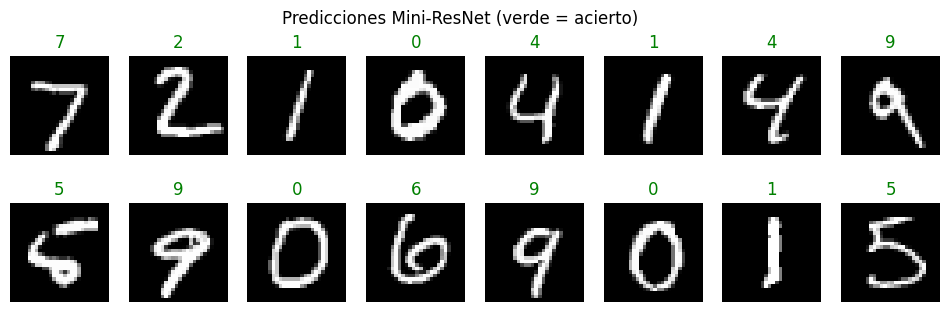

In [9]:
class ResBlock(nn.Module):
    def __init__(self, c_in, c_out, stride=1):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False); self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False);     self.bn2 = nn.BatchNorm2d(c_out)
        self.skip = (nn.Identity() if stride == 1 and c_in == c_out else
                     nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out)))
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.skip(x))          # ← la conexión residual

class MiniResNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU())
        self.layers = nn.Sequential(ResBlock(16, 16), ResBlock(16, 32, 2), ResBlock(32, 64, 2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(64, 10))
    def forward(self, x): return self.head(self.layers(self.stem(x)))

aug = transforms.Compose([transforms.RandomAffine(10, translate=(0.1, 0.1)),
                          transforms.ToTensor(), norm])
train_aug = datasets.MNIST("data", train=True, download=True, transform=aug)
train_dl_aug = DataLoader(train_aug, batch_size=128, shuffle=True, num_workers=2)

EPOCHS = 4
resnet = MiniResNet().to(device)
opt = torch.optim.AdamW(resnet.parameters(), lr=3e-3, weight_decay=1e-2)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-3, epochs=EPOCHS, steps_per_epoch=len(train_dl_aug))
h6 = fit(resnet, train_dl_aug, test_dl, EPOCHS, opt, sched,
         loss_fn=nn.CrossEntropyLoss(label_smoothing=0.1), clip=1.0)
show_predictions(resnet, title="Mini-ResNet")
results["6 Mini-ResNet"] = (h6["acc"][-1], n_params(resnet))
torch.save(resnet.state_dict(), "mini_resnet.pth")      # guardar pesos

## 🔹 Nivel 7 · Tiny Vision Transformer (ViT)
La imagen se corta en **parches**, cada parche es un "token" y la **auto-atención** los relaciona entre sí.

Época 1/4 | loss 1.3713 | acc 0.8077 | 127.7s
Época 2/4 | loss 0.7551 | acc 0.8918 | 128.4s
Época 3/4 | loss 0.5642 | acc 0.9015 | 128.1s
Época 4/4 | loss 0.4699 | acc 0.9208 | 129.4s


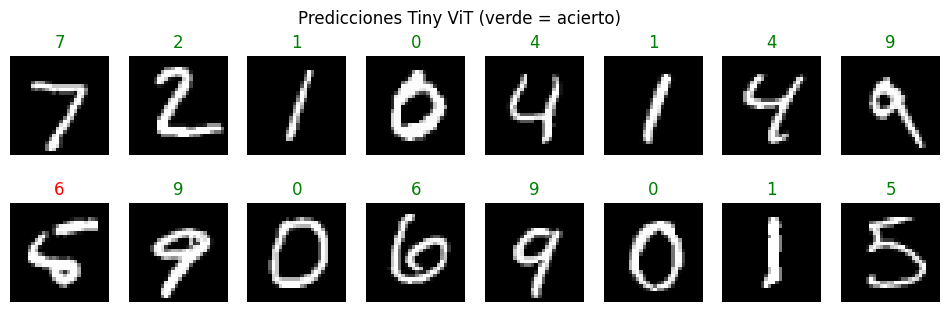

In [10]:
class TinyViT(nn.Module):
    def __init__(self, patch=4, dim=64, depth=2, heads=4, n_cls=10):
        super().__init__()
        self.patch = nn.Conv2d(1, dim, patch, patch)            # 28/4 = 7 → 49 parches
        self.cls = nn.Parameter(torch.zeros(1, 1, dim))
        self.pos = nn.Parameter(torch.randn(1, 50, dim) * 0.02)
        layer = nn.TransformerEncoderLayer(dim, heads, dim * 2, dropout=0.1, batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim); self.head = nn.Linear(dim, n_cls)
    def forward(self, x):
        x = self.patch(x).flatten(2).transpose(1, 2)           # (B, 49, dim)
        x = torch.cat([self.cls.expand(len(x), -1, -1), x], 1) + self.pos
        return self.head(self.norm(self.encoder(x)[:, 0]))

vit = TinyViT().to(device)
opt = torch.optim.AdamW(vit.parameters(), lr=1e-3, weight_decay=1e-2)
h7 = fit(vit, train_dl_aug, test_dl, epochs=4, opt=opt)
show_predictions(vit, title="Tiny ViT")
results["7 Tiny ViT"] = (h7["acc"][-1], n_params(vit))

## 🏁 Comparativa final (imagen para el cierre del video)

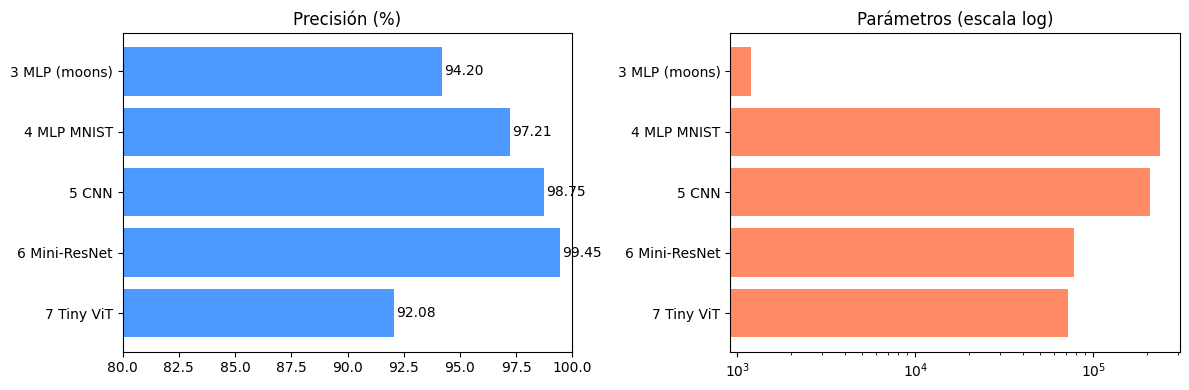

In [11]:
names = [k for k, v in results.items() if v[0] is not None]
accs = [results[k][0] * 100 for k in names]
pars = [results[k][1] for k in names]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].barh(names, accs, color="#4C9AFF"); ax[0].set_xlim(80, 100)
ax[0].set_title("Precisión (%)"); ax[0].invert_yaxis()
for i, a in enumerate(accs): ax[0].text(a + 0.1, i, f"{a:.2f}", va="center")
ax[1].barh(names, pars, color="#FF8A65"); ax[1].set_xscale("log")
ax[1].set_title("Parámetros (escala log)"); ax[1].invert_yaxis()
plt.tight_layout(); plt.savefig("comparativa.png", dpi=200); plt.show()